# Cobre — análisis de corredores
Datos de julio a diciembre de 2025. Este notebook responde las tres partes del assessment y conserva los CSV originales.

**Criterios:** volumen = número de intentos; valor = suma en USD, incluidos fallos; éxito = éxitos / intentos. La comisión del 0,5% es un supuesto del caso, no ingreso contable observado. El promedio mensual divide el semestre entre seis.

Ejecutar todas las celdas desde la carpeta del proyecto. Se regeneran las tablas, los tres gráficos y el Excel. El Excel es una exportación de resultados, no un dashboard ni un modelo con fórmulas. Los detalles de reproducción están en README.md.
**Índice de respuestas**

- [Parte 1 — Análisis de datos](#parte1).
- [Parte 2 — Análisis de causas raíz](#parte2).
- [Parte 3 — Recomendación estratégica](#parte3).
- [Desarrollo técnico y evidencia](#desarrollo-tecnico).

Los CSV originales sustentan las cifras. Los enlaces internos permiten consultar los cálculos sin salir del notebook.


<a id="parte1"></a>
## Parte 1 — Respuestas a las diez preguntas

Las respuestas se agrupan en los tres apartados del assessment. Cada una presenta el resultado, su significado para Cobre y la ubicación del cálculo y de la tabla en `cobre_analysis.xlsx`. Todas corresponden a julio–diciembre de 2025.

- [1. Desempeño de corredores](#parte1-corredores): preguntas P1–P4.
- [2. Comportamiento de usuarios](#parte1-usuarios): preguntas P5–P7.
- [3. Patrones temporales](#parte1-tiempo): preguntas P8–P10.

Las secciones técnicas numeradas más abajo conservan los cálculos ejecutados y las referencias utilizadas por el informe. Volumen significa número de intentos; el valor y el ticket promedio incluyen operaciones exitosas y fallidas.


<a id="parte1-corredores"></a>
### 1. Desempeño de corredores

<a id="p1"></a>
#### P1. ¿Cuáles son los cinco principales corredores por volumen de transacciones?

**Resultado, de mayor a menor:** USD→MXN: **17.407** intentos; USD→COP: **15.066**; MXN→COP: **7.600**; COP→USD: **5.988**; MXN→USD: **3.939**.

**Para Cobre:** USD→MXN concentra la mayor actividad y USD→COP ocupa el segundo lugar. El ranking mide operaciones iniciadas, no únicamente pagos completados.

**Cálculo y evidencia:** `COUNT(*)` por corredor. [Sección técnica 1, ejecución In [2]](#evidencia-corredores), primera tabla; Excel **Tabla 2**, hoja **«Corridor Volume»**, rango **A4:B9**.

<a id="p2"></a>
#### P2. ¿Cuáles son los cinco principales corredores por valor total en USD?

**Resultado, de mayor a menor:** USD→MXN: **USD 126.567.091,02**; USD→COP: **USD 77.818.846,45**; MXN→COP: **USD 27.520.177,55**; COP→USD: **USD 26.914.517,46**; MXN→USD: **USD 22.647.843,43**.

**Para Cobre:** USD→MXN también lidera por valor registrado. En estos datos ambos rankings coinciden, aunque se calcularon por separado. Estos importes incluyen pagos fallidos y no representan ingresos ni valor liquidado.

**Cálculo y evidencia:** `SUM(amount_usd)` por corredor, ordenado por valor descendente. [Sección técnica 1, In [2]](#evidencia-corredores), segunda tabla; Excel **Tabla 3**, hoja **«Corridor Value»**, rango **A4:B9**.

<a id="p3"></a>
#### P3. ¿Qué corredores tienen las mayores tasas de éxito?

**Resultado, de mayor a menor:** COP→USD: **95,72%**; MXN→USD: **95,28%**; USD→COP: **94,90%**; MXN→COP: **94,83%**; USD→MXN: **81,75%**.

**Para Cobre:** COP→USD presenta la mayor tasa observada; USD→MXN, la menor. Esto respalda revisar los fallos de USD→MXN. Las pequeñas diferencias entre los otros corredores no prueban superioridad estadística.

**Cálculo y evidencia:** pagos exitosos / total de intentos por corredor. [Sección técnica 1, In [2]](#evidencia-corredores), tercera tabla; Excel **Tabla 4**, hoja **«Success Rates»**, rango **A4:E9**.

<a id="p4"></a>
#### P4. ¿Cuál es el ticket promedio por corredor?

**Resultado:** USD→MXN: **USD 7.271,05**; USD→COP: **USD 5.165,20**; MXN→COP: **USD 3.621,08**; COP→USD: **USD 4.494,74**; MXN→USD: **USD 5.749,64**.

**Para Cobre:** USD→MXN tiene el mayor ticket promedio. Esta medida permite distinguir el número de operaciones de su importe medio; no mide por sí sola confiabilidad ni rentabilidad.

**Cálculo y evidencia:** `AVG(amount_usd)` por corredor, incluidos éxitos y fallos. [Sección técnica 1, In [2]](#evidencia-corredores), segunda tabla; Excel **Tabla 3**, hoja **«Corridor Value»**, corredores en **A5:A9** y ticket en **C5:C9**.


<a id="parte1-usuarios"></a>
### 2. Comportamiento de usuarios

<a id="p5"></a>
#### P5. ¿Cuál es el promedio de transacciones por usuario?

**Resultado:** **10,00 intentos por usuario durante el semestre**: 50.000 / 5.000.

**Para Cobre:** es una referencia de frecuencia sobre todos los usuarios registrados. Los 5.000 tienen operaciones, pero solo 4.243 presentan `status=active`; no se debe confundir actividad transaccional con ese estado administrativo. No es un promedio mensual.

**Cálculo y evidencia:** total de intentos / usuarios registrados. [Sección técnica 2, In [3]](#evidencia-usuarios), salida de texto y variable `avg_per_user`. Excel **Tabla 6**, hoja **«Country Analysis»**: sumar **C5:C6** (intentos) y dividir entre la suma de **G5:G6** (registrados). La columna I muestra los promedios por país, no un promedio global que deba promediarse sin ponderar.

<a id="p6"></a>
#### P6. ¿Cuáles son los diez usuarios con mayor volumen de transacciones?

**Resultado:** con **21 intentos**: `USR_1798`, `USR_1843`, `USR_4714` y `USR_4823`. Con **20 intentos**, completan el top 10: `USR_0336`, `USR_1186`, `USR_1853`, `USR_2234`, `USR_2316` y `USR_2419`.

**Para Cobre:** identifica los usuarios con mayor frecuencia registrada, no necesariamente los más rentables. Hay diez usuarios empatados con 20 intentos; se incluyen los seis primeros por `user_id` ascendente para entregar exactamente diez filas. Ese desempate no implica mayor importancia comercial.

**Cálculo y evidencia:** conteo por usuario; orden por cantidad descendente y `user_id` ascendente. [Sección técnica 2, In [3]](#evidencia-usuarios), primera tabla; Excel **Tabla 5**, hoja **«Top Users»**, rango **A4:B14**.

<a id="p7"></a>
#### P7. ¿Cómo difiere el comportamiento entre usuarios de México y Colombia?

**Resultado:** México registra **29.526 intentos** de **2.957 usuarios**, frente a **20.474 intentos** de **2.043 usuarios** en Colombia. La frecuencia por registrado es muy similar: **9,99** y **10,02**, respectivamente. El ticket colombiano es ligeramente mayor: **USD 5.678,59**, frente a **USD 5.595,24** en México. Las tasas de éxito son **90,46%** y **90,42%**, respectivamente. La mezcla de corredores también es casi idéntica: USD→MXN representa **34,7%** de los intentos de usuarios mexicanos y **35,0%** de los colombianos; USD→COP, **30,3%** y **29,8%**.

**Para Cobre:** el mayor volumen mexicano corresponde a una base de usuarios más amplia, con frecuencia por usuario similar. Los usuarios de ambos países se comportan igual en frecuencia, ticket, confiabilidad y corredores usados: la diferencia es de tamaño de base, no de comportamiento. La comparación usa el país del usuario, no el país de origen o destino del pago.

**Cálculo y evidencia:** unión por `user_id` y agregación por país; promedio de importe, tasa de éxito e intentos / registrados. [Sección técnica 2, In [3]](#evidencia-usuarios), segunda tabla y explicación posterior; Excel **Tabla 6**, hoja **«Country Analysis»**, rango **A4:I6**, y **Tabla 22**, hoja **«Country Corridors»**.


<a id="parte1-tiempo"></a>
### 3. Patrones temporales

<a id="p8"></a>
#### P8. ¿Qué días de la semana tienen el mayor volumen transaccional?

**Resultado:** por total registrado lideran **martes (7.337)**, **domingo (7.199)** y **miércoles (7.190)**. Al dividir por las fechas observadas de cada día, **domingo** tiene el mayor promedio: **276,88 intentos por fecha**, frente a **271,74** el martes. Hay 27 martes y 26 domingos en la cobertura observada.

**Para Cobre:** el martes lidera el conteo bruto, pero no el promedio diario. Para interpretar la carga operativa conviene considerar ambos: el número desigual de fechas influye en el ranking acumulado. Esta pregunta trata de volumen; las tasas de fallo por día se analizan por separado en la Parte 2.

**Cálculo y evidencia:** conteo por día de semana y total / fechas observadas. [Sección técnica 4, In [5]](#evidencia-tiempo), primera tabla y explicación; Excel **Tabla 7**, hoja **«Weekly»**, rango **A4:D11**.

<a id="p9"></a>
#### P9. ¿Existen patrones horarios relevantes?

**Resultado:** los registros se concentran en las horas **08 a 19**. El máximo es a las **10 h, con 4.304 intentos**, seguido de las **13 h, con 4.227**. El mínimo entre las horas con actividad es a las **16 h, con 4.102**. Las demás horas no tienen registros.

**Para Cobre:** la diferencia entre las horas activas es modesta; no se observa un pico muy marcado. La hora se interpreta tal como aparece en el archivo, sin zona horaria declarada. La ausencia de registros fuera de esas horas no demuestra por sí sola un horario formal de operación.

**Cálculo y evidencia:** conteo por hora; se muestran las 24 horas, con cero donde no hay registros. [Sección técnica 4, In [5]](#evidencia-tiempo), segunda tabla y explicación; Excel **Tabla 8**, hoja **«Hourly»**, rango **A4:B28**; 10 h en **A15:B15**, 13 h en **A18:B18** y 16 h en **A21:B21**.

<a id="p10"></a>
#### P10. ¿El volumen creció o disminuyó durante los seis meses?

**Resultado:** en ventanas comparables de días 1–30, el volumen pasa de **8.232 intentos en julio a 8.184 en diciembre (−0,58%)**. La serie es: julio **8.232**, agosto **8.236**, septiembre **8.082**, octubre **8.128**, noviembre **8.336** y diciembre **8.184**. Los totales originales pasan de **8.479 a 8.184 (−3,48%)**, con distinta cantidad de fechas observadas.

**Para Cobre:** la actividad comparable permanece prácticamente estable, con fluctuaciones y una ligera caída entre extremos; no demuestra crecimiento ni caída sostenidos. No hay registros del 31 de diciembre y se desconoce el motivo. Comparar días 1–30 evita mezclar ventanas de distinta duración, sin imputar actividad ni ajustar por festivos o composición de días laborables.

**Cálculo y evidencia:** conteos mensuales originales y para días 1–30; cambio julio–diciembre = diciembre / julio − 1. [Sección técnica 4, In [5]](#evidencia-tiempo), tercera tabla y explicación. Excel **Tabla 9**, hoja **«Monthly»**, rango **A4:G10**: totales originales en **B5 y B10**, ventanas comparables en **E5 y E10**. La columna G contiene cambios respecto al mes anterior, no directamente el cambio julio–diciembre. Respaldo visual existente: **Figura 2**, sección técnica 8.

**Cobertura de la Parte 1:** las diez preguntas tienen respuesta y evidencia. Las limitaciones de cobertura temporal, zona horaria y definición de usuario están indicadas junto a las respuestas correspondientes.


<a id="parte2"></a>
## Parte 2 — Análisis de causas raíz

### 1. ¿Qué patrones presentan las transacciones fallidas?

USD→MXN falla en 3.177 de 17.407 operaciones (18,25%); los otros cuatro corredores, en 4,92% en conjunto.

- **Segmento:** el patrón está en el segmento registrado en cada transacción, no en el del cliente (`users.csv`: 17,9–18,7%). Enterprise falla 23,9%; retail, 19,5%; SME, 14,1%. Retail aporta 52% de los fallos y enterprise, 58% del valor fallido.
- **Importe:** va ligado a ese segmento. Fallan más los pagos mayores de USD 10.000 (23,4%) y los menores de USD 2.000 (20,7%) que los intermedios (13,7%).
- **Días:** el viernes (18,4%) no difiere del resto (18,2%). La variación diaria es la esperable por azar y la tasa se mantiene todos los meses.
- **Otros corredores:** fallan cerca de 5% en todos los segmentos. El problema es propio de USD→MXN y permanente.

### 2. ¿Cuáles son tres posibles causas raíz?

1. Controles de cumplimiento o límites del banco receptor en pagos altos.
2. Datos del beneficiario incorrectos, como la CLABE, en pagos pequeños.
3. Fallas del proveedor o de la integración en México: incluso el mejor segmento casi triplica el 5%.

### 3. ¿Cómo validar cada hipótesis?

Con los códigos de rechazo por segmento e importe, los campos bancarios rechazados y los registros del proveedor; después, una prueba controlada de cada corrección. Los CSV no incluyen esos datos.

### 4. ¿Cuál es la comisión mensual potencial no percibida?

USD 25.105.200,71 fallidos × 0,5% ÷ 6 meses = **USD 20.921 mensuales**.

### 5. ¿Cuál sería el incremento mensual al reducir los fallos al 5%?

Se recuperarían 2.307 operaciones; al ticket medio fallido, **USD 15.192 mensuales**, 18% más que la comisión actual del corredor. Cifra antes de costos.

**Recomendación:** empezar por los pagos enterprise, que concentran 58% del valor fallido.

Evidencia: [segmentación](#evidencia-segmentos), [patrones](#evidencia-fallos) y [escenarios financieros](#evidencia-finanzas); tablas 10–17 y 21 del Excel; Figura 3.

<a id="parte3"></a>
## Parte 3 — Recomendación estratégica

Memorando de inversión para 2026

### 1. ¿Qué corredor recomendaría y por qué?

Recomiendo priorizar **USD→MXN**. Es el corredor más grande: 17.407 operaciones (34,8%), USD 126,6 millones de valor registrado (45% del total) y el mayor ticket medio (USD 7.271). Con la comisión supuesta del 0,5% genera **USD 84.552 mensuales**, frente a USD 61.548 de USD→COP.

Además, es el único corredor con una palanca de crecimiento medible en los datos: pierde 18,25% de los pagos que sus clientes ya intentan hacer. Crecer aquí no exige captar demanda nueva, sino completar la que ya existe.

### 2. ¿Cómo se compara con las alternativas?

- **USD→COP:** 15.066 operaciones y 94,90% de éxito. Es confiable, pero su actividad no crece (−1,53% entre julio y diciembre) y los datos no muestran una palanca concreta.
- **MXN→COP, COP→USD y MXN→USD:** éxito cercano a 95%, pero cada uno genera menos de USD 22.000 mensuales; sus variaciones (+0,8% a +2,8%) parten de bases pequeñas.

Ningún corredor muestra crecimiento sostenido en el semestre: la actividad total varía −0,58%. Comparación completa: [sección técnica 7](#evidencia-estrategia), tablas 14, 18 y 23 del Excel.

### 3. ¿Qué acciones específicas recomendaría?

1. **Diagnóstico (primer mes):** obtener del proveedor en México los códigos de rechazo por segmento e importe.
2. **Pagos altos (58% del valor fallido):** validar límites y requisitos de cumplimiento antes de enviar el pago.
3. **Pagos pequeños (52% de los fallos):** validar la CLABE y los datos del beneficiario al capturar la orden.
4. **Proveedor:** si los rechazos provienen de la integración, evaluar un segundo proveedor de pagos en México.
5. **Seguimiento:** medir cada semana la tasa de éxito por segmento e invertir en captación solo cuando baje de forma sostenida.

### 4. ¿Cuál sería el impacto esperado?

- **Reducir los fallos al 5%:** 2.307 operaciones recuperadas en el semestre, **USD 15.192 mensuales adicionales (+18%)**, unos USD 182.000 al año.
- **Escenario intermedio (10% de fallos):** USD 9.463 mensuales adicionales.
- **Crecimiento posterior:** cada 10% de volumen adicional sobre el corredor ya reparado aportaría unos USD 9.974 mensuales. Ese 10% es un supuesto, no una proyección de los datos.

Las cifras usan la comisión supuesta del 0,5% y son antes de costos. Los CSV no miden el tamaño del mercado ni la complejidad operativa; esta última es el principal riesgo, porque la solución depende de terceros en México.

<a id="desarrollo-tecnico"></a>
## Desarrollo del análisis y evidencia

Las secciones técnicas siguientes conservan su numeración y muestran las consultas, cálculos y tablas ejecutadas que respaldan las tres partes anteriores.


In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / 'data/transactions.csv').exists(), 'Ejecutar desde la raíz del proyecto'
source_hashes = {name: hashlib.sha256((ROOT / 'data' / name).read_bytes()).hexdigest()
                 for name in ['transactions.csv', 'users.csv']}
assert source_hashes == {
    'transactions.csv': '52f0aeddd4e4f13a79856bc1aee4425052f28e9d7cdd6f2f7255e0b62427003b',
    'users.csv': '14084aea86486ae7d98265d4238bc1426d3e273c7ef4227719ce2ba78ee22371'}
t = pd.read_csv(ROOT / 'data/transactions.csv')
u = pd.read_csv(ROOT / 'data/users.csv')
t['transaction_date'] = pd.to_datetime(t['transaction_date'], format='%Y-%m-%d', errors='raise')
t['hour'] = pd.to_datetime(t['transaction_time'], format='%H:%M:%S', errors='raise').dt.hour
u['registration_date'] = pd.to_datetime(u['registration_date'], format='%Y-%m-%d', errors='raise')
t['month'] = t['transaction_date'].dt.strftime('%Y-%m')
t['day'] = t['transaction_date'].dt.day_name()
t['failed'] = t['status'].eq('failed')
t['successful_value'] = t['amount_usd'].where(~t['failed'], 0)
t['failed_value'] = t['amount_usd'].where(t['failed'], 0)
joined = t.merge(u, on='user_id', suffixes=('_tx', '_user'), how='left', validate='many_to_one', indicator=True)
con = duckdb.connect()
con.register('transactions', t)
con.register('users', u)
checks = []
def check(name, condition, detail=''):
    checks.append({'Control': name, 'Resultado': 'OK' if bool(condition) else 'ERROR', 'Detalle': detail})
    assert bool(condition), name
check('Filas originales', len(t) == 50000 and len(u) == 5000)
check('Sin nulos', not t.isna().any().any() and not u.isna().any().any())
check('IDs únicos', t.transaction_id.is_unique and u.user_id.is_unique)
check('JOIN sin pérdida ni multiplicación', len(joined) == len(t) and joined['_merge'].eq('both').all())
check('Estados permitidos', set(t.status) == {'success', 'failed'} and set(u.status) == {'active', 'inactive'})
check('Segmentos permitidos', set(t.user_segment) == set(u.user_segment) == {'retail','sme','enterprise'})
check('País de usuario permitido', set(u.country) == {'Mexico', 'Colombia'})
check('Importes positivos finitos con centavos', np.isfinite(t.amount_usd).all() and t.amount_usd.gt(0).all() and np.allclose(t.amount_usd*100, (t.amount_usd*100).round(), rtol=0, atol=1e-6))
check('Registro anterior a operación', joined.transaction_date.ge(joined.registration_date).all())
mapping = {'USD': 'US', 'MXN': 'MX', 'COP': 'CO'}
parts = t.corridor.str.split('_', expand=True)
check('Corredor y países consistentes', parts[0].map(mapping).eq(t.source_country).all() and parts[1].map(mapping).eq(t.destination_country).all())
check('Seis meses esperados', sorted(t.month.unique()) == [f'2025-{m:02}' for m in range(7,13)])
print(f'{len(t):,} transacciones; {len(u):,} usuarios. Cobertura observada: {t.transaction_date.min().date()} a {t.transaction_date.max().date()}.')
print(f'Fallo global observado: {t.failed.mean():.2%}; el 5% del enunciado se trata como referencia y objetivo.')

50,000 transacciones; 5,000 usuarios. Cobertura observada: 2025-07-01 a 2025-12-30.
Fallo global observado: 9.56%; el 5% del enunciado se trata como referencia y objetivo.


<a id="evidencia-corredores"></a>
## 1. Corredores
Los rankings se calculan por separado, aunque coinciden en estos datos. Las comisiones estimadas sobre operaciones exitosas se muestran después en la comparación estratégica.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 2. Intentos por corredor — hoja «Corridor Volume».
- Tabla 3. Valor y ticket por corredor — hoja «Corridor Value».
- Tabla 4. Éxito por corredor — hoja «Success Rates».

In [2]:
corridors = con.execute("""
SELECT corridor, COUNT(*) AS total_transactions, SUM(amount_usd) AS total_usd,
       AVG(amount_usd) AS avg_transaction_usd,
       SUM(CASE WHEN status='success' THEN 1 ELSE 0 END) AS successful,
       SUM(CASE WHEN status='failed' THEN 1 ELSE 0 END) AS failed,
       AVG(CASE WHEN status='success' THEN 1.0 ELSE 0 END) AS success_rate,
       SUM(CASE WHEN status='success' THEN amount_usd ELSE 0 END) AS successful_value
FROM transactions GROUP BY corridor ORDER BY total_transactions DESC, corridor
""").df()
independent = t.groupby('corridor').agg(total_transactions=('transaction_id','size'), total_usd=('amount_usd','sum'), avg_transaction_usd=('amount_usd','mean'), successful=('failed',lambda s: (~s).sum()), failed=('failed','sum'), success_rate=('failed',lambda s: (~s).mean()), successful_value=('successful_value','sum')).sort_index()
pd.testing.assert_frame_equal(corridors.set_index('corridor').sort_index(), independent, check_dtype=False, rtol=1e-12, atol=1e-7)
check('Pandas frente a DuckDB en todos los corredores', True)
top_corridors = corridors[['corridor','total_transactions']].head(5)
corridor_value = corridors[['corridor','total_usd','avg_transaction_usd']].sort_values(['total_usd','corridor'], ascending=[False,True]).head(5)
corridor_success = corridors[['corridor','total_transactions','successful','failed','success_rate']].sort_values(['success_rate','corridor'],ascending=[False,True])
display(top_corridors, corridor_value.round(2), corridor_success)

,corridor,total_transactions
0,USD_MXN,17407
1,USD_COP,15066
2,MXN_COP,7600
3,COP_USD,5988
4,MXN_USD,3939


,corridor,total_usd,avg_transaction_usd
0,USD_MXN,1.265671e+08,7271.05
1,USD_COP,7.781885e+07,5165.20
2,MXN_COP,2.752018e+07,3621.08
3,COP_USD,2.691452e+07,4494.74
4,MXN_USD,2.264784e+07,5749.64


,corridor,total_transactions,successful,failed,success_rate
3,COP_USD,5988,5732.0,256.0,0.957248
4,MXN_USD,3939,3753.0,186.0,0.952780
1,USD_COP,15066,14297.0,769.0,0.948958
2,MXN_COP,7600,7207.0,393.0,0.948289
0,USD_MXN,17407,14230.0,3177.0,0.817487


<a id="evidencia-usuarios"></a>
## 2. Usuarios y empates
El promedio incluye los 5.000 usuarios registrados; todos tienen al menos una operación. “Usuarios con operaciones” no equivale a `status=active`.

Hay cuatro usuarios con 21 operaciones y diez con 20. Para entregar exactamente diez filas, el empate se ordena por `user_id` ascendente. Este desempate administrativo no implica que los seis seleccionados sean más importantes que los otros cuatro.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 5. Diez usuarios con más intentos — hoja «Top Users».
- Tabla 6. Usuarios por país — hoja «Country Analysis».
- Tabla 22. Corredores por país del usuario — hoja «Country Corridors».

In [3]:
user_counts = con.execute('SELECT user_id, COUNT(*) AS total_transactions FROM transactions GROUP BY user_id ORDER BY total_transactions DESC, user_id ASC').df()
top_users = user_counts.head(10).copy()
check('Top usuarios coincide con Pandas', top_users.equals(t.groupby('user_id').size().reset_index(name='total_transactions').sort_values(['total_transactions','user_id'],ascending=[False,True]).head(10).reset_index(drop=True)))
country_analysis = joined.groupby('country').agg(users_with_transactions=('user_id','nunique'),total_transactions=('transaction_id','size'), total_usd=('amount_usd','sum'), avg_amount_usd=('amount_usd','mean'), success_rate=('failed','mean')).reset_index()
country_analysis['success_rate'] = 1-country_analysis['success_rate']
registered = u.groupby('country').agg(registered_users=('user_id','size'),active_status_users=('status',lambda s: s.eq('active').sum())).reset_index()
country_analysis = country_analysis.merge(registered,on='country',validate='one_to_one')
country_analysis['avg_transactions_per_registered_user'] = country_analysis.total_transactions/country_analysis.registered_users
country_analysis = country_analysis.sort_values('total_transactions',ascending=False)
country_corridors = joined.groupby(['country','corridor']).size().rename('total_transactions').reset_index()
country_corridors['corridor_share'] = country_corridors.total_transactions/country_corridors.groupby('country').total_transactions.transform('sum')
country_corridors = country_corridors.sort_values(['country','total_transactions'],ascending=[False,False]).reset_index(drop=True)
avg_per_user = len(t)/len(u)
print(f'Promedio semestral: {avg_per_user:.2f}. Usuarios con operaciones: {t.user_id.nunique()}; status activo: {u.status.eq("active").sum()}.')
display(top_users, country_analysis.round(4), country_corridors.round(4))
print('México concentra más operaciones por tener más usuarios. La frecuencia es similar: 9,99 frente a 10,02; el ticket colombiano es ligeramente mayor (USD 5.678,59 frente a USD 5.595,24).')
print('La mezcla de corredores es casi idéntica en ambos países: la diferencia es de tamaño de base, no de comportamiento.')

Promedio semestral: 10.00. Usuarios con operaciones: 5000; status activo: 4243.


,user_id,total_transactions
0,USR_1798,21
1,USR_1843,21
2,USR_4714,21
3,USR_4823,21
4,USR_0336,20
5,USR_1186,20
6,USR_1853,20
7,USR_2234,20
8,USR_2316,20
9,USR_2419,20


,country,users_with_transactions,total_transactions,total_usd,avg_amount_usd,success_rate,registered_users,active_status_users,avg_transactions_per_registered_user
1,Mexico,2957,29526,1.652051e+08,5595.2404,0.9042,2957,2523,9.9851
0,Colombia,2043,20474,1.162634e+08,5678.5879,0.9046,2043,1720,10.0215


,country,corridor,total_transactions,corridor_share
0,Mexico,USD_MXN,10232,0.3465
1,Mexico,USD_COP,8956,0.3033
2,Mexico,MXN_COP,4512,0.1528
3,Mexico,COP_USD,3495,0.1184
4,Mexico,MXN_USD,2331,0.0789
5,Colombia,USD_MXN,7175,0.3504
6,Colombia,USD_COP,6110,0.2984
7,Colombia,MXN_COP,3088,0.1508
8,Colombia,COP_USD,2493,0.1218
9,Colombia,MXN_USD,1608,0.0785


México concentra más operaciones por tener más usuarios. La frecuencia es similar: 9,99 frente a 10,02; el ticket colombiano es ligeramente mayor (USD 5.678,59 frente a USD 5.595,24).
La mezcla de corredores es casi idéntica en ambos países: la diferencia es de tamaño de base, no de comportamiento.


<a id="evidencia-segmentos"></a>
## 3. Investigación del segmento
Los dos archivos traen un campo `user_segment` y miden cosas distintas. En `users.csv` hay un segmento por cliente. En `transactions.csv` el segmento se registra en cada operación: cambia para casi todos los usuarios, incluso en un mismo día, y va ligado al importe. En USD→MXN, las operaciones retail van de USD 1.050 a 4.199; las SME, de USD 3.500 a 10.500; y las enterprise, de USD 10.500 a 34.993.

Para describir **clientes** se usa `users.user_segment`; para describir **operaciones**, el campo transaccional. Los fallos de USD→MXN no distinguen entre tipos de cliente (17,9–18,7%), pero sí entre tipos de operación: enterprise 23,9%, retail 19,5% y SME 14,1%. En los otros cuatro corredores, los tres segmentos fallan cerca de 5%.

Los archivos no incluyen un diccionario de datos ni fechas de vigencia, por lo que no se puede saber si el segmento del cliente cambió en el tiempo. No se modifica ningún CSV.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 15. Discrepancias de segmento — hoja «Segment Audit».
- Tabla 10. Fallos por segmento de cliente — hoja «Failure Segments».
- Tabla 16. Fallos por segmento de la transacción — hoja «Segment Sensitivity».
- Tabla 21. Fallos por segmento: USD→MXN frente al resto — hoja «Failure Tiers».

In [4]:
mismatch = joined.user_segment_tx.ne(joined.user_segment_user)
segments_per_user = t.groupby('user_id').user_segment.nunique()
same_day = t.groupby(['user_id','transaction_date']).user_segment.nunique()
segment_audit = pd.DataFrame([
    ['Transacciones con segmentos distintos', int(mismatch.sum()), len(t)],
    ['Usuarios afectados', joined.loc[mismatch,'user_id'].nunique(),len(u)],
    ['Usuarios con más de un segmento transaccional', int(segments_per_user.gt(1).sum()),len(u)],
    ['Usuario-día con más de un segmento', int(same_day.gt(1).sum()),len(same_day)]
],columns=['Medida','Casos','Universo'])
segment_audit['Proporcion'] = segment_audit.Casos/segment_audit.Universo
segment_month = joined.assign(mismatch=mismatch).groupby('month').agg(mismatches=('mismatch','sum'),total=('transaction_id','size')).reset_index()
mxn = joined.loc[joined.corridor.eq('USD_MXN')].copy()
def segment_summary(column):
    return mxn.groupby(column).agg(total_transactions=('transaction_id','size'),failed=('failed','sum'), failure_rate=('failed','mean')).reset_index().rename(columns={column:'user_segment'}).sort_values(['failure_rate','user_segment'],ascending=[False,True])
failure_segments = segment_summary('user_segment_user')
segment_sensitivity = segment_summary('user_segment_tx')
check('Ambos análisis conservan el universo USD MXN', failure_segments.total_transactions.sum()==segment_sensitivity.total_transactions.sum()==len(mxn) and failure_segments.failed.sum()==segment_sensitivity.failed.sum()==3177)
# Segmento de la transacción: USD→MXN frente a los otros cuatro corredores.
scope = np.where(joined.corridor.eq('USD_MXN'), 'USD_MXN', 'Otros corredores')
failure_tiers = joined.assign(ambito=scope).groupby(['ambito','user_segment_tx']).agg(
    total_transactions=('transaction_id','size'), failed=('failed','sum'), failure_rate=('failed','mean'),
    failed_value_usd=('failed_value','sum'), min_amount_usd=('amount_usd','min'), max_amount_usd=('amount_usd','max')
).reset_index().rename(columns={'user_segment_tx':'user_segment'})
failure_tiers['failed_share'] = failure_tiers.failed/failure_tiers.groupby('ambito').failed.transform('sum')
failure_tiers['failed_value_share'] = failure_tiers.failed_value_usd/failure_tiers.groupby('ambito').failed_value_usd.transform('sum')
failure_tiers = failure_tiers.sort_values(['ambito','failure_rate'],ascending=[False,False]).reset_index(drop=True)
check('Fallos por segmento transaccional reconcilian', failure_tiers.total_transactions.sum()==len(t) and failure_tiers.failed.sum()==int(t.failed.sum()))
display(segment_audit, segment_month, failure_segments, segment_sensitivity, failure_tiers.round(4))
client, tx = failure_segments.set_index('user_segment').failure_rate, failure_tiers.loc[failure_tiers.ambito.eq('USD_MXN')].set_index('user_segment')
rest = failure_tiers.loc[failure_tiers.ambito.eq('Otros corredores')].set_index('user_segment').failure_rate
print(f'USD→MXN por segmento del cliente: entre {client.min():.1%} y {client.max():.1%}; no distingue tipos de cliente.')
print('USD→MXN por segmento de la transacción: ' + '; '.join(f'{s} {r.failure_rate:.1%} ({r.failed_share:.0%} de los fallos, {r.failed_value_share:.0%} del valor fallido)' for s, r in tx.iterrows()) + '.')
print(f'Otros corredores por segmento de la transacción: entre {rest.min():.1%} y {rest.max():.1%}.')

,Medida,Casos,Universo,Proporcion
0,Transacciones con segmentos distintos,30435,50000,0.608700
1,Usuarios afectados,4984,5000,0.996800
2,Usuarios con más de un segmento transaccional,4970,5000,0.994000
3,Usuario-día con más de un segmento,805,48675,0.016538


,month,mismatches,total
0,2025-07,5167,8479
1,2025-08,5188,8524
2,2025-09,4866,8082
3,2025-10,5136,8395
4,2025-11,5119,8336
5,2025-12,4959,8184


,user_segment,total_transactions,failed,failure_rate
2,sme,6242,1169,0.187280
1,retail,8455,1522,0.180012
0,enterprise,2710,486,0.179336


,user_segment,total_transactions,failed,failure_rate
0,enterprise,2653,634,0.238975
1,retail,8550,1667,0.194971
2,sme,6204,876,0.141199


,ambito,user_segment,total_transactions,failed,failure_rate,failed_value_usd,min_amount_usd,max_amount_usd,failed_share,failed_value_share
0,USD_MXN,enterprise,2653,634,0.2390,14526057.33,10502.70,34993.08,0.1996,0.5786
1,USD_MXN,retail,8550,1667,0.1950,4347510.02,1050.46,4199.33,0.5247,0.1732
2,USD_MXN,sme,6204,876,0.1412,6231633.36,3501.72,10499.92,0.2757,0.2482
3,Otros corredores,retail,16314,818,0.0501,1407769.18,540.03,3358.58,0.5100,0.1842
4,Otros corredores,enterprise,4878,244,0.0500,3763405.40,5400.39,27941.76,0.1521,0.4924
5,Otros corredores,sme,11401,542,0.0475,2472023.00,1800.07,8398.62,0.3379,0.3234


USD→MXN por segmento del cliente: entre 17.9% y 18.7%; no distingue tipos de cliente.
USD→MXN por segmento de la transacción: enterprise 23.9% (20% de los fallos, 58% del valor fallido); retail 19.5% (52% de los fallos, 17% del valor fallido); sme 14.1% (28% de los fallos, 25% del valor fallido).
Otros corredores por segmento de la transacción: entre 4.8% y 5.0%.


<a id="evidencia-tiempo"></a>
## 4. Tiempo y cobertura comparable
No hay registros del 31 de diciembre. No sabemos si es cierre del extracto o ausencia real de actividad; no se imputa un día ni se afirma que diciembre esté necesariamente incompleto.

Se conservan los totales originales y se comparan **días 1–30 en cada mes**, seis ventanas de 30 días presentes en los datos. La métrica diaria por días observados se incluye como sensibilidad. Comparar extremos no demuestra una tendencia sostenida, y las ventanas no ajustan festivos ni mezcla de días laborables. La hora se usa tal como viene; no hay zona horaria declarada.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 7. Actividad por día de semana — hoja «Weekly».
- Tabla 8. Actividad por hora — hoja «Hourly».
- Tabla 9. Actividad mensual comparable — hoja «Monthly».
- Tabla 14. Evolución por corredor — hoja «Corridor Growth».

In [5]:
weekly = t.groupby('day').agg(total_transactions=('transaction_id','size'),observed_dates=('transaction_date','nunique')).reset_index()
weekly['transactions_per_observed_day'] = weekly.total_transactions/weekly.observed_dates
weekly = weekly.sort_values('total_transactions',ascending=False)
hourly = t.groupby('hour').size().reindex(range(24),fill_value=0).reset_index(name='total_transactions')
monthly = t.groupby('month').agg(total_transactions=('transaction_id','size'),observed_days=('transaction_date','nunique')).reset_index()
monthly['transactions_per_observed_day'] = monthly.total_transactions/monthly.observed_days
comparable = t.loc[t.transaction_date.dt.day.le(30)]
check('Ventanas comparables de 30 fechas', comparable.groupby('month').transaction_date.nunique().eq(30).all())
matched = comparable.groupby('month').size()
monthly['transactions_days_1_30'] = monthly.month.map(matched)
monthly['daily_days_1_30'] = monthly.transactions_days_1_30/30
monthly['change_previous_comparable'] = monthly.transactions_days_1_30.pct_change()
corridor_growth = t.groupby(['corridor','month']).agg(transactions=('transaction_id','size'),total_usd=('amount_usd','sum')).reset_index()
cg = comparable.groupby(['corridor','month']).size().rename('transactions_days_1_30').reset_index()
corridor_growth = corridor_growth.merge(cg,on=['corridor','month'],validate='one_to_one')
display(weekly.round(2), hourly, monthly.round(4))
print('Martes: 7.337 operaciones, pero domingo tiene el mayor promedio por fecha observada. La cobertura desigual influye en el ranking bruto.')
print('Horas observadas: 08–19; máximo a las 10 (4.304), mínimo entre horas con actividad a las 16 (4.102). Diferencia modesta; no se atribuye a una causa.')
print('Total bruto julio-diciembre: -3,48%; días observados: -0,26%; ventanas 1–30: -0,58%. Actividad comparable prácticamente estable, con fluctuaciones.')

,day,total_transactions,observed_dates,transactions_per_observed_day
5,Tuesday,7337,27,271.74
3,Sunday,7199,26,276.88
6,Wednesday,7190,26,276.54
0,Friday,7126,26,274.08
1,Monday,7110,26,273.46
2,Saturday,7040,26,270.77
4,Thursday,6998,26,269.15


,hour,total_transactions
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,4205
9,9,4106


,month,total_transactions,observed_days,transactions_per_observed_day,transactions_days_1_30,daily_days_1_30,change_previous_comparable
0,2025-07,8479,31,273.5161,8232,274.4000,NaN
1,2025-08,8524,31,274.9677,8236,274.5333,0.0005
2,2025-09,8082,30,269.4000,8082,269.4000,-0.0187
3,2025-10,8395,31,270.8065,8128,270.9333,0.0057
4,2025-11,8336,30,277.8667,8336,277.8667,0.0256
5,2025-12,8184,30,272.8000,8184,272.8000,-0.0182


Martes: 7.337 operaciones, pero domingo tiene el mayor promedio por fecha observada. La cobertura desigual influye en el ranking bruto.
Horas observadas: 08–19; máximo a las 10 (4.304), mínimo entre horas con actividad a las 16 (4.102). Diferencia modesta; no se atribuye a una causa.
Total bruto julio-diciembre: -3,48%; días observados: -0,26%; ventanas 1–30: -0,58%. Actividad comparable prácticamente estable, con fluctuaciones.


<a id="evidencia-fallos"></a>
## 5. Fallos y posibles causas
La tasa USD→MXN observada es 18,25% (el caso menciona 15%). Los otros cuatro corredores fallan 4,92% en conjunto, en línea con el 5% del enunciado; el 9,56% global incluye a USD→MXN.

**Importe.** La tasa es más alta en los extremos: 20,7% hasta USD 2.000 y 23,4% por encima de USD 10.000, frente a 13,7% entre USD 5.000 y 10.000.

**Días.** El viernes no presenta una tasa mayor que el resto de la semana, a diferencia de lo que plantea el enunciado. La dispersión de la tasa diaria es similar a la que produciría el azar con unas 95 operaciones por fecha, y la tasa mensual se mantiene entre 16,8% y 19,4%. No hay evidencia de incidentes puntuales: el problema es permanente.

**Hipótesis.** (1) Controles de cumplimiento o límites del banco receptor en pagos altos: obtener los códigos de rechazo y compararlos por importe. (2) Datos del beneficiario incorrectos en pagos pequeños: inspeccionar los campos rechazados y probar una validación previa. (3) Fallas del proveedor o de la integración en México, que elevan la tasa de todo el corredor: revisar registros, tiempos de respuesta y timeouts. Los CSV no contienen esos campos, por lo que las tres siguen siendo hipótesis.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 11. Fallos por importe — hoja «Failure Amounts».
- Tabla 12. Fallos por día de semana — hoja «Failure Days».

In [6]:
mxn['amount_range'] = pd.cut(mxn.amount_usd,[0,2000,5000,10000,np.inf],labels=['0 < USD ≤ 2.000','2.000 < USD ≤ 5.000','5.000 < USD ≤ 10.000','USD > 10.000'])
amount_analysis = mxn.groupby('amount_range',observed=False).agg(total_transactions=('transaction_id','size'),failed=('failed','sum'),failure_rate=('failed','mean')).reset_index()
amount_analysis['amount_range'] = amount_analysis.amount_range.astype(str)
daily_failures = mxn.groupby('day').agg(total_transactions=('transaction_id','size'),failed=('failed','sum'),failure_rate=('failed','mean')).reset_index().sort_values('failure_rate',ascending=False)
check('Rangos de importe cubren todo USD MXN', amount_analysis.total_transactions.sum()==len(mxn))
# Viernes frente al resto, dispersión diaria frente al azar y estabilidad mensual.
friday = mxn.day.eq('Friday')
friday_rate, other_days_rate = mxn.loc[friday,'failed'].mean(), mxn.loc[~friday,'failed'].mean()
by_date = mxn.groupby('transaction_date').failed.agg(['mean','size'])
p_mxn = mxn.failed.mean()
expected_sd = math.sqrt(p_mxn*(1-p_mxn)/by_date['size'].mean())
monthly_fail = mxn.groupby('month').failed.mean()
others_rate = joined.loc[joined.corridor.ne('USD_MXN'),'failed'].mean()
display(amount_analysis, daily_failures)
rates = amount_analysis.set_index('amount_range').failure_rate
print(f'USD→MXN {p_mxn:.2%} frente a {others_rate:.2%} en los otros cuatro corredores.')
print(f'Importe: {rates.iloc[0]:.1%} hasta USD 2.000; {rates.iloc[2]:.1%} entre USD 5.000 y 10.000; {rates.iloc[3]:.1%} por encima de USD 10.000.')
print(f'Viernes {friday_rate:.2%} frente a {other_days_rate:.2%} el resto de la semana.')
print(f'Tasa diaria: desviación observada {by_date["mean"].std():.1%}; esperable por azar {expected_sd:.1%} con {by_date["size"].mean():.0f} operaciones por fecha.')
print(f'Tasa mensual: entre {monthly_fail.min():.1%} y {monthly_fail.max():.1%}.')

,amount_range,total_transactions,failed,failure_rate
0,0 < USD ≤ 2.000,2576,532,0.206522
1,2.000 < USD ≤ 5.000,7332,1319,0.179896
2,5.000 < USD ≤ 10.000,4409,604,0.136993
3,USD > 10.000,3090,722,0.233657


,day,total_transactions,failed,failure_rate
5,Tuesday,2571,487,0.189420
1,Monday,2584,486,0.188080
4,Thursday,2383,447,0.187579
0,Friday,2445,449,0.183640
2,Saturday,2429,444,0.182791
3,Sunday,2511,441,0.175627
6,Wednesday,2484,423,0.170290


USD→MXN 18.25% frente a 4.92% en los otros cuatro corredores.
Importe: 20.7% hasta USD 2.000; 13.7% entre USD 5.000 y 10.000; 23.4% por encima de USD 10.000.
Viernes 18.36% frente a 18.23% el resto de la semana.
Tasa diaria: desviación observada 4.4%; esperable por azar 4.0% con 95 operaciones por fecha.
Tasa mensual: entre 16.8% y 19.4%.


<a id="evidencia-finanzas"></a>
## 6. Impacto financiero y escenario al 5%
La base es el valor fallido USD→MXN multiplicado por 0,5% y dividido entre seis. Es comisión potencial no capturada, no pérdida contable.

**Escenario principal por conteo:** para no superar 5% en el semestre, quedan como máximo `floor(17.407 × 5%) = 870` fallos; se recuperan 2.307. Se supone que la selección recuperada tiene el ticket medio de las fallidas. Es una expectativa, no una selección real. No garantiza 5% en cada mes.

**Sensibilidad con selección explícita:** recuperar las 2.307 fallas menores o las 2.307 mayores da extremos ilustrativos, con desempate por ID. **Escenario por valor:** dejar como fallido 5% del valor total es otro supuesto; no equivale a 5% del conteo porque el ticket fallido medio difiere del ticket total. No se usa 5% del valor actualmente fallido como si fuera 5% del universo.

Se suponen intentos recuperables, sin doble conteo de reintentos, cobro efectivo del fee y volumen estable. No conocemos reintentos, comisiones reales ni costos; no puede estimarse ganancia neta.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 13. Comisión potencial no capturada — hoja «Financial Impact».
- Tabla 17. Escenarios de recuperación — hoja «Financial Scenarios».

In [7]:
fee, months, target_rate = 0.005, 6, 0.05
failed_mxn = mxn.loc[mxn.failed].sort_values(['amount_usd','transaction_id'])
N, F = len(mxn), len(failed_mxn)
total_value, failed_value = mxn.amount_usd.sum(), failed_mxn.amount_usd.sum()
target_failures = math.floor(N*target_rate)
recover_count = F-target_failures
loss = failed_value*fee/months
recover_expected_value = recover_count*failed_mxn.amount_usd.mean()
count_gain = recover_expected_value*fee/months
value_gain = (failed_value-total_value*target_rate)*fee/months
low = failed_mxn.head(recover_count)
high = failed_mxn.sort_values(['amount_usd','transaction_id'],ascending=[False,True]).head(recover_count)
scenarios = pd.DataFrame([
    ['Conteo: ticket fallido medio',recover_count,recover_expected_value,count_gain],
    ['Conteo: menores importes',len(low),low.amount_usd.sum(),low.amount_usd.sum()*fee/months],
    ['Conteo: mayores importes',len(high),high.amount_usd.sum(),high.amount_usd.sum()*fee/months],
    ['Valor: 5% del importe total',None,failed_value-total_value*target_rate,value_gain]
],columns=['Escenario','Operaciones recuperadas','Valor recuperado USD','Comision adicional USD mes'])
financial_impact = pd.DataFrame([[N,F,F/N,total_value,failed_value,fee,months,loss]],columns=['Intentos','Fallos','Tasa fallo','Valor intentado USD','Valor fallido USD','Fee supuesto','Meses','Comision no capturada USD mes'])
sql_fin = con.execute("SELECT COUNT(*), SUM(CASE WHEN status='failed' THEN 1 ELSE 0 END), SUM(amount_usd), SUM(CASE WHEN status='failed' THEN amount_usd ELSE 0 END) FROM transactions WHERE corridor='USD_MXN'").fetchone()
check('Finanzas Pandas frente a DuckDB', np.allclose([N,F,total_value,failed_value],sql_fin,rtol=0,atol=1e-6))
check('Objetivo por conteo y selecciones', target_failures/N<=.05 and (target_failures+1)/N>.05 and low.transaction_id.nunique()==high.transaction_id.nunique()==recover_count)
check('Esperanza dentro de extremos', scenarios.iloc[1,3]<=count_gain<=scenarios.iloc[2,3])
display(financial_impact, scenarios.round(2))
print(f'Ticket fallido medio: {failed_value/F:,.2f}; ticket de todos los intentos: {total_value/N:,.2f}.')
print(f'Principal: recuperar {recover_count:,} operaciones; fallos restantes {target_failures:,} ({target_failures/N:.5%}); comisión adicional media USD {count_gain:,.2f}/mes.')

,Intentos,Fallos,Tasa fallo,Valor intentado USD,Valor fallido USD,Fee supuesto,Meses,Comision no capturada USD mes
0,17407,3177,0.182513,1.265671e+08,25105200.71,0.005,6,20921.000592


,Escenario,Operaciones recuperadas,Valor recuperado USD,Comision adicional USD mes
0,Conteo: ticket fallido medio,2307.0,18230311.00,15191.93
1,Conteo: menores importes,2307.0,8276398.63,6897.00
2,Conteo: mayores importes,2307.0,23510768.31,19592.31
3,Valor: 5% del importe total,NaN,18776846.16,15647.37


Ticket fallido medio: 7,902.17; ticket de todos los intentos: 7,271.05.
Principal: recuperar 2,307 operaciones; fallos restantes 870 (4.99799%); comisión adicional media USD 15,191.93/mes.


<a id="evidencia-estrategia"></a>
## 7. Comparación estratégica y decisión
Se prioriza USD→MXN: es el corredor con más operaciones, 45% del valor registrado y la mayor comisión estimada. También es el único con una palanca de crecimiento medible en los datos, porque pierde 18,25% de los pagos que sus clientes ya intentan hacer. USD→COP es confiable y segundo en escala, pero su actividad no crece y los datos no muestran una palanca concreta. MXN→COP, COP→USD y MXN→USD tienen tasas de éxito cercanas a 95% sobre bases mucho menores.

El impacto se estima en tres escenarios: reducir los fallos de USD→MXN al 5%, reducirlos al 10% y, como supuesto, aumentar 10% el volumen del corredor ya reparado. Los dos primeros usan el ticket medio de las operaciones fallidas y la comisión supuesta del 0,5%, antes de costos. El tercero no sale de los datos: la actividad del semestre es estable.

Los datos no miden demanda futura, tamaño de mercado, costos ni complejidad operativa. El principal riesgo es que la solución dependa de terceros en México.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 18. Comparación estratégica de corredores — hoja «Strategy».
- Tabla 23. Impacto esperado en USD→MXN — hoja «Growth Impact».

In [8]:
pivot = corridor_growth.pivot(index='month',columns='corridor',values='transactions_days_1_30')
strategy = corridors[['corridor','total_transactions','total_usd','success_rate','successful_value']].copy()
strategy.insert(3, 'value_share', strategy.total_usd/strategy.total_usd.sum())
strategy['estimated_fee_usd_month'] = strategy.successful_value*fee/months
strategy['jul_days_1_30'] = strategy.corridor.map(pivot.loc['2025-07'])
strategy['dec_days_1_30'] = strategy.corridor.map(pivot.loc['2025-12'])
strategy['comparable_change'] = strategy.dec_days_1_30/strategy.jul_days_1_30-1
strategy['decision'] = strategy.corridor.map({'USD_MXN':'Prioridad: reparar fallos para crecer','USD_COP':'Alternativa confiable, sin palanca identificada','MXN_COP':'Menor escala','COP_USD':'Menor escala; mayor tasa de éxito','MXN_USD':'Menor escala'})
# Impacto esperado en USD→MXN.
mxn_fee_month = strategy.set_index('corridor').loc['USD_MXN','estimated_fee_usd_month']
recover_10 = F-math.floor(N*0.10)
gain_10 = recover_10*failed_mxn.amount_usd.mean()*fee/months
growth_10 = (mxn_fee_month+count_gain)*0.10
growth_impact = pd.DataFrame([
    ['Reducir fallos al 5%', recover_count, count_gain],
    ['Reducir fallos al 10%', recover_10, gain_10],
    ['Supuesto: +10% de volumen sobre el corredor reparado', None, growth_10]
],columns=['Escenario','Operaciones recuperadas','additional_fee_usd_month'])
growth_impact['additional_fee_usd_year'] = growth_impact.additional_fee_usd_month*12
growth_impact['change_vs_current'] = growth_impact.additional_fee_usd_month/mxn_fee_month
display(strategy.round(4), growth_impact.round(4))
print(f'USD→MXN: comisión estimada USD {mxn_fee_month:,.2f}/mes; {strategy.set_index("corridor").loc["USD_MXN","value_share"]:.1%} del valor registrado.')
print(f'Reducir los fallos al 5%: +USD {count_gain:,.2f}/mes ({count_gain/mxn_fee_month:.1%}), USD {count_gain*12:,.0f} al año. Al 10%: +USD {gain_10:,.2f}/mes.')
print(f'Supuesto de +10% de volumen sobre el corredor reparado: +USD {growth_10:,.2f}/mes. No es una proyección de los datos.')

,corridor,total_transactions,total_usd,value_share,success_rate,successful_value,estimated_fee_usd_month,jul_days_1_30,dec_days_1_30,comparable_change,decision
0,USD_MXN,17407,1.265671e+08,0.4497,0.8175,1.014619e+08,84551.5753,2863,2798,-0.0227,Prioridad: reparar fallos para crecer
1,USD_COP,15066,7.781885e+07,0.2765,0.9490,7.385767e+07,61548.0625,2490,2452,-0.0153,"Alternativa confiable, sin palanca identificada"
2,MXN_COP,7600,2.752018e+07,0.0978,0.9483,2.611323e+07,21761.0288,1238,1267,0.0234,Menor escala
3,COP_USD,5988,2.691452e+07,0.0956,0.9572,2.579293e+07,21494.1076,988,996,0.0081,Menor escala; mayor tasa de éxito
4,MXN_USD,3939,2.264784e+07,0.0805,0.9528,2.149435e+07,17911.9571,653,671,0.0276,Menor escala


,Escenario,Operaciones recuperadas,additional_fee_usd_month,additional_fee_usd_year,change_vs_current
0,Reducir fallos al 5%,2307.0,15191.9258,182303.1100,0.1797
1,Reducir fallos al 10%,1437.0,9462.8511,113554.2128,0.1119
2,Supuesto: +10% de volumen sobre el corredor re...,NaN,9974.3501,119692.2013,0.1180


USD→MXN: comisión estimada USD 84,551.58/mes; 45.0% del valor registrado.
Reducir los fallos al 5%: +USD 15,191.93/mes (18.0%), USD 182,303 al año. Al 10%: +USD 9,462.85/mes.
Supuesto de +10% de volumen sobre el corredor reparado: +USD 9,974.35/mes. No es una proyección de los datos.


## 8. Visualizaciones
El gráfico mensual compara ventanas de igual duración y muestra también los totales originales. El eje comienza en cero y el subtítulo declara el alcance.

**Figura 1. Intentos de pago por corredor.** Primera imagen de la celda siguiente; archivo `corridor_volume.png`.

**Figura 2. Actividad mensual y comparación de 30 días.** Segunda imagen de la celda siguiente; archivo `monthly_trend.png`.

**Figura 3. Tasa de fallo por segmento de la transacción.** Tercera imagen de la celda siguiente; archivo `failure_by_segment.png`. Compara USD→MXN con los otros cuatro corredores.

Las figuras ya forman parte de las salidas ejecutadas; las tablas 2–23 están tituladas en el Excel.

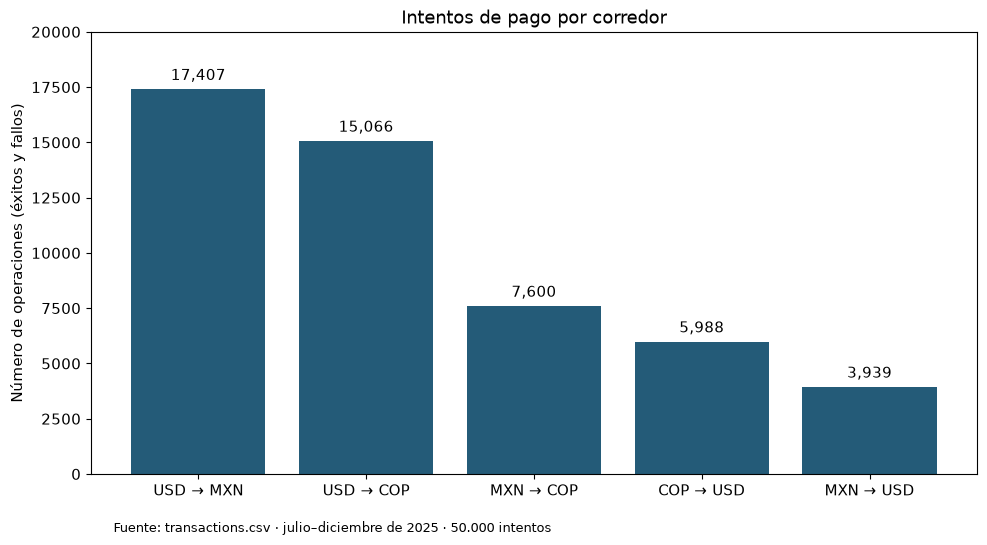

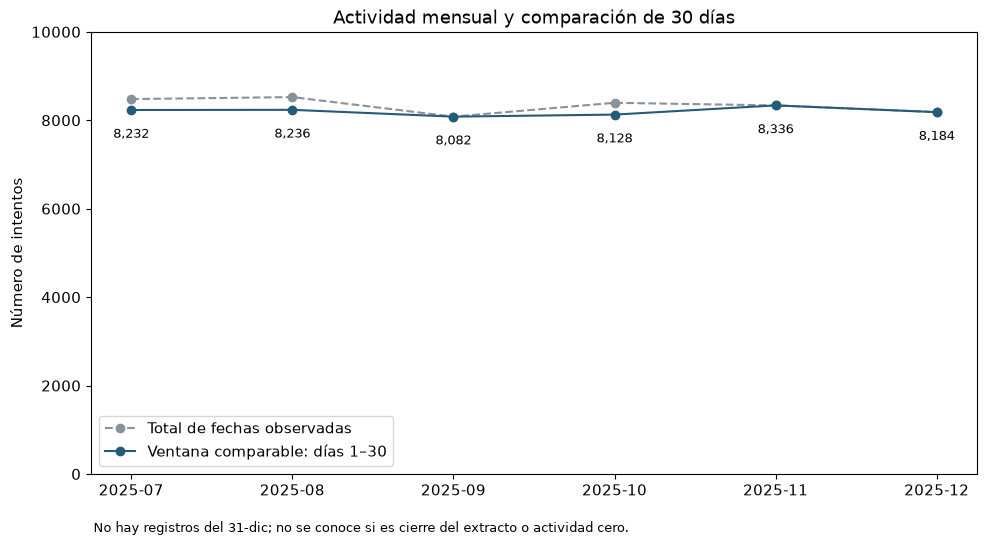

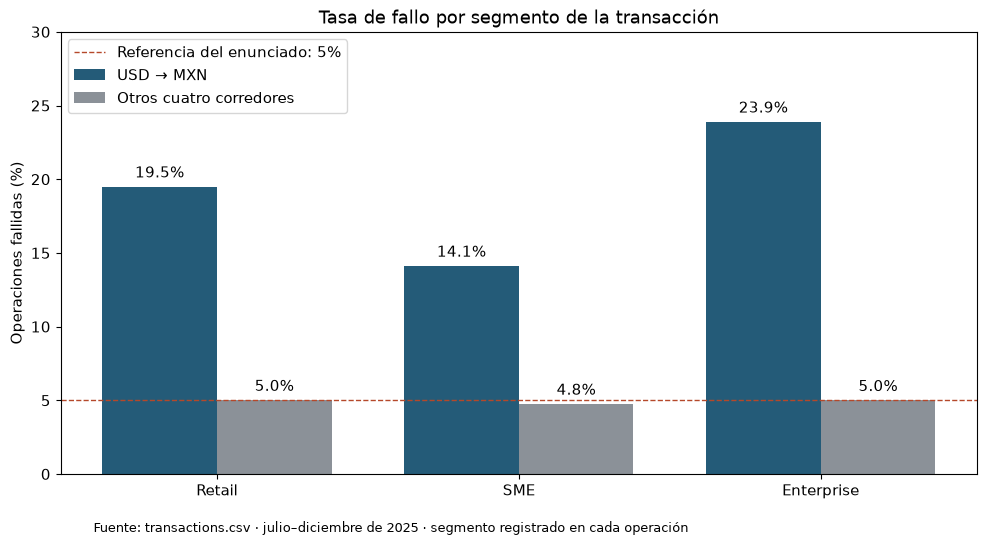

In [9]:
plt.rcParams.update({'font.size': 11})
fig, ax = plt.subplots(figsize=(10,5.5))
bars = ax.bar(top_corridors.corridor.str.replace('_',' → '),top_corridors.total_transactions,color='#245B78')
ax.bar_label(bars,labels=[f'{v:,}' for v in top_corridors.total_transactions],padding=4)
ax.set(title='Intentos de pago por corredor',ylabel='Número de operaciones (éxitos y fallos)',ylim=(0,20000))
fig.text(.12,.02,'Fuente: transactions.csv · julio–diciembre de 2025 · 50.000 intentos',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(ROOT/'corridor_volume.png',dpi=160);plt.show();plt.close(fig)
fig, ax = plt.subplots(figsize=(10,5.5))
ax.plot(monthly.month,monthly.total_transactions,marker='o',linestyle='--',color='#8B9198',label='Total de fechas observadas')
ax.plot(monthly.month,monthly.transactions_days_1_30,marker='o',color='#245B78',label='Ventana comparable: días 1–30')
for x,y in zip(monthly.month,monthly.transactions_days_1_30): ax.annotate(f'{y:,}',(x,y),xytext=(0,-20),textcoords='offset points',ha='center',fontsize=9)
ax.set(title='Actividad mensual y comparación de 30 días',ylabel='Número de intentos',ylim=(0,10000));ax.legend(loc='lower left')
fig.text(.10,.02,'No hay registros del 31-dic; no se conoce si es cierre del extracto o actividad cero.',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(ROOT/'monthly_trend.png',dpi=160);plt.show();plt.close(fig)
seg_order = ['retail','sme','enterprise']
tier_rates = failure_tiers.pivot(index='user_segment',columns='ambito',values='failure_rate').loc[seg_order]*100
fig, ax = plt.subplots(figsize=(10,5.5))
x, width = np.arange(len(seg_order)), .38
bars_mxn = ax.bar(x-width/2,tier_rates['USD_MXN'],width,color='#245B78',label='USD → MXN')
bars_rest = ax.bar(x+width/2,tier_rates['Otros corredores'],width,color='#8B9198',label='Otros cuatro corredores')
ax.bar_label(bars_mxn,labels=[f'{v:.1f}%' for v in tier_rates['USD_MXN']],padding=4)
ax.bar_label(bars_rest,labels=[f'{v:.1f}%' for v in tier_rates['Otros corredores']],padding=4)
ax.axhline(5,color='#B5482A',linestyle='--',linewidth=1,label='Referencia del enunciado: 5%')
ax.set_xticks(x,['Retail','SME','Enterprise'])
ax.set(title='Tasa de fallo por segmento de la transacción',ylabel='Operaciones fallidas (%)',ylim=(0,30));ax.legend(loc='upper left')
fig.text(.10,.02,'Fuente: transactions.csv · julio–diciembre de 2025 · segmento registrado en cada operación',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(ROOT/'failure_by_segment.png',dpi=160);plt.show();plt.close(fig)

## 9. Exportación y controles finales
El control «Tres indicadores clave» comprueba solo tres comisiones estimadas, no el documento completo.

Los valores se exportan sin redondear su precisión interna; los formatos controlan cómo se muestran. Tasas sin observaciones quedan vacías y se explican. El Excel se genera en la celda siguiente con `openpyxl`, a partir de las mismas tablas del notebook. La exportación no modifica datos fuente.

**Tablas de referencia en `cobre_analysis.xlsx`:**

- Tabla 19. Definiciones y limitaciones — hoja «Methodology».
- Tabla 20. Controles del análisis — hoja «Checks».
- Tablas 21 a 23 — hojas «Failure Tiers», «Country Corridors» y «Growth Impact».

In [10]:
methodology = pd.DataFrame([
['Fuentes','transactions.csv y users.csv originales; 50.000 intentos y 5.000 usuarios.'],
['Segmento del cliente','users.user_segment: un valor por cliente. Sin historial, no se certifica el segmento histórico.'],
['Segmento de la transacción','transactions.user_segment: se registra por operación y va ligado al importe; 30.435 discrepancias con el del cliente.'],
['Cobertura','01-jul a 30-dic de 2025. El motivo de la ausencia del 31-dic no se conoce.'],
['Tiempo','Comparación principal: días 1–30 de cada mes. Se mantienen totales y promedio por día observado.'],
['Usuarios','Promedio sobre todos los registrados. Usuarios con operaciones no significa status activo.'],
['Top 10','Cantidad descendente, user_id ascendente. Cuatro usuarios con 21 y diez con 20.'],
['Comisiones','0,5% supuesto; promedio del semestre / 6; no ingreso contable ni margen neto.'],
['Objetivo 5%','Por conteo semestral: 870 fallos como máximo, 2.307 recuperaciones; ticket fallido medio.'],
['Sensibilidad financiera','Extremos por 2.307 menores/mayores importes. 5% del valor es un supuesto distinto.'],
['Horas','Hora original sin zona horaria informada; no se atribuye causalidad.'],
['Ausencias','Sin códigos de error, reintentos, tarifas reales, costos, demanda o mercado.'],
['Formato','Exportación estática de tablas; se regenera al ejecutar el notebook.'],
['IA','ChatGPT, Codex y Claude Code apoyaron el código, la revisión de cálculos y la redacción; detalle en README.md.']
],columns=['Tema','Criterio'])
for name,digest in source_hashes.items():
    check('CSV intacto '+name, hashlib.sha256((ROOT/'data'/name).read_bytes()).hexdigest()==digest)
check('Reconciliación de volúmenes', top_corridors.total_transactions.sum()==monthly.total_transactions.sum()==country_analysis.total_transactions.sum()==len(t))
check('Tres indicadores clave', round(loss,2)==20921.00 and round(count_gain,2)==15191.93 and round(mxn_fee_month,2)==84551.58)
check('Población con estados inactivos conservada', joined.status_user.eq('inactive').sum()==7526)
tables = {
'Corridor Volume':top_corridors,'Corridor Value':corridor_value,'Success Rates':corridor_success,
'Top Users':top_users,'Country Analysis':country_analysis,'Weekly':weekly,'Hourly':hourly,'Monthly':monthly,
'Failure Segments':failure_segments,'Failure Amounts':amount_analysis,'Failure Days':daily_failures,
'Financial Impact':financial_impact,'Corridor Growth':corridor_growth,
'Segment Audit':segment_audit,'Segment Sensitivity':segment_sensitivity,'Financial Scenarios':scenarios,
'Strategy':strategy,'Methodology':methodology,'Checks':pd.DataFrame(checks),
'Failure Tiers':failure_tiers,'Country Corridors':country_corridors,'Growth Impact':growth_impact}
sheet_titles = {
    'Corridor Volume': 'Tabla 2. Intentos por corredor',
    'Corridor Value': 'Tabla 3. Valor y ticket por corredor',
    'Success Rates': 'Tabla 4. Éxito por corredor',
    'Top Users': 'Tabla 5. Diez usuarios con más intentos',
    'Country Analysis': 'Tabla 6. Usuarios por país',
    'Weekly': 'Tabla 7. Actividad por día de semana',
    'Hourly': 'Tabla 8. Actividad por hora',
    'Monthly': 'Tabla 9. Actividad mensual comparable',
    'Failure Segments': 'Tabla 10. Fallos por segmento de cliente',
    'Failure Amounts': 'Tabla 11. Fallos por importe',
    'Failure Days': 'Tabla 12. Fallos por día de semana',
    'Financial Impact': 'Tabla 13. Comisión potencial no capturada',
    'Corridor Growth': 'Tabla 14. Evolución por corredor',
    'Segment Audit': 'Tabla 15. Discrepancias de segmento',
    'Segment Sensitivity': 'Tabla 16. Fallos por segmento de la transacción',
    'Financial Scenarios': 'Tabla 17. Escenarios de recuperación',
    'Strategy': 'Tabla 18. Comparación estratégica de corredores',
    'Methodology': 'Tabla 19. Definiciones y limitaciones',
    'Checks': 'Tabla 20. Controles del análisis',
    'Failure Tiers': 'Tabla 21. Fallos por segmento: USD→MXN frente al resto',
    'Country Corridors': 'Tabla 22. Corredores por país del usuario',
    'Growth Impact': 'Tabla 23. Impacto esperado en USD→MXN',
}
column_labels = {
    'corridor':'Corredor', 'total_transactions':'Intentos', 'total_usd':'Valor intentado USD',
    'avg_transaction_usd':'Ticket medio USD', 'successful':'Éxitos', 'failed':'Fallos', 'success_rate':'Éxito %',
    'user_id':'Usuario', 'country':'País del usuario', 'users_with_transactions':'Usuarios con operaciones',
    'avg_amount_usd':'Ticket medio USD', 'registered_users':'Usuarios registrados', 'active_status_users':'Usuarios status activo',
    'avg_transactions_per_registered_user':'Intentos por registrado', 'day':'Día', 'observed_dates':'Fechas observadas',
    'transactions_per_observed_day':'Intentos por día observado', 'hour':'Hora original', 'month':'Mes', 'observed_days':'Días observados',
    'transactions_days_1_30':'Intentos días 1–30', 'daily_days_1_30':'Intentos diarios días 1–30', 'change_previous_comparable':'Cambio mes anterior días 1–30 %',
    'user_segment':'Segmento', 'failure_rate':'Fallo %', 'amount_range':'Rango de importe USD', 'transactions':'Intentos',
    'successful_value':'Valor exitoso USD', 'estimated_fee_usd_month':'Fee estimado USD mes', 'jul_days_1_30':'Julio días 1–30',
    'dec_days_1_30':'Diciembre días 1–30', 'comparable_change':'Cambio julio–dic días 1–30 %', 'decision':'Criterio de decisión',
    'ambito':'Ámbito', 'failed_value_usd':'Valor fallido USD', 'min_amount_usd':'Importe mínimo USD', 'max_amount_usd':'Importe máximo USD',
    'failed_share':'% de los fallos', 'failed_value_share':'% del valor fallido', 'corridor_share':'% de los intentos del país',
    'value_share':'% del valor total', 'additional_fee_usd_month':'Comisión adicional USD mes',
    'additional_fee_usd_year':'Comisión adicional USD año', 'change_vs_current':'Cambio sobre comisión actual %'}
sheet_notes = {
    'Corridor Volume':'Fuente: transactions.csv. Julio–diciembre 2025. Éxitos y fallos; ranking por número de intentos.',
    'Corridor Value':'Fuente: transactions.csv. Valor incluye intentos fallidos; no es volumen liquidado.',
    'Success Rates':'Fuente: transactions.csv. Éxitos / intentos. Tasas almacenadas como proporciones.',
    'Top Users':'Fuente: transactions.csv. Cantidad DESC, user_id ASC. 4 usuarios con 21; 10 empatados con 20. Se muestran 10.',
    'Country Analysis':'Fuentes: users.csv y transactions.csv. País del usuario; JOIN many-to-one. Usuarios con operaciones ≠ status activo.',
    'Weekly':'Fuente: transactions.csv. Ranking bruto y sensibilidad por número de fechas observadas.',
    'Hourly':'Fuente: transactions.csv. Sin zona horaria informada. Horas sin registros se muestran con cero.',
    'Monthly':'Fuente: transactions.csv. Comparación principal días 1–30. Motivo de ausencia del 31-dic desconocido. Primer cambio no aplica.',
    'Failure Segments':'USD→MXN. Segmento del cliente: users.csv. La tasa no distingue tipos de cliente. Ver Segment Sensitivity.',
    'Failure Amounts':'USD→MXN. Fuente: transactions.csv. La tasa es mayor en los importes extremos que en los intermedios.',
    'Failure Days':'USD→MXN. El viernes no difiere del resto; las diferencias entre días son las esperables por azar.',
    'Financial Impact':'USD→MXN. Fee supuesto 0,5%. Promedio semestral / 6. Comisión potencial, no pérdida contable.',
    'Corridor Growth':'Fuente: transactions.csv. Se conservan totales y ventanas de 30 días. Sin imputar actividad.',
    'Segment Audit':'JOIN de ambos CSV por user_id. Evidencia de discrepancia; no determina cuál es el segmento histórico.',
    'Segment Sensitivity':'USD→MXN. Segmento registrado en cada operación (transactions.csv); va ligado al importe y describe la operación, no al cliente.',
    'Financial Scenarios':'USD→MXN. 2.307 recuperaciones; 870 fallos restantes (≤5% semestral). Escenario por valor no define conteo.',
    'Strategy':'Fuente: transactions.csv. Fee 0,5% sobre valor exitoso / 6. Cambio julio–diciembre en días 1–30. Mercado, costos y complejidad no medidos.',
    'Methodology':'Definiciones y límites. Resultados estáticos; cálculos reproducibles en analysis.ipynb.',
    'Checks':'Controles del notebook. «Tres indicadores clave» verifica solo tres comisiones estimadas; no comprueba todo el informe.',
    'Failure Tiers':'Fuente: transactions.csv. Segmento registrado en cada operación. Porcentajes calculados dentro de cada ámbito.',
    'Country Corridors':'Fuentes: users.csv y transactions.csv. País del usuario; porcentaje sobre los intentos de cada país.',
    'Growth Impact':'USD→MXN. Fee supuesto 0,5%, antes de costos. Ticket medio de las operaciones fallidas. El +10% de volumen es un supuesto.'}
check('Todas las hojas tienen título y nota', set(tables) == set(sheet_titles) == set(sheet_notes))

import re
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

def excel_value(v):
    """Convierte valores de Pandas/NumPy a tipos nativos; los vacíos quedan como celda vacía."""
    if v is None or (isinstance(v, float) and math.isnan(v)) or v is pd.NA:
        return None
    return v.item() if isinstance(v, np.generic) else v

def export_excel(tables, path):
    """Una hoja por tabla: título en la fila 1, nota en la 2, encabezados en la 4 y datos desde la 5."""
    wb = Workbook()
    wb.remove(wb.active)
    ink, band = '172B3A', 'EFF4F7'
    for name, df in tables.items():
        ws = wb.create_sheet(name)
        ws.sheet_view.showGridLines = False
        n_rows, n_cols = df.shape
        last = get_column_letter(n_cols)
        for row, text, height, font in [(1, sheet_titles[name], 44, Font(name='Arial', size=15, bold=True, color=ink)),
                                        (2, sheet_notes[name], 48, Font(name='Arial', size=11, color=ink))]:
            ws.merge_cells(f'A{row}:{last}{row}')
            cell = ws.cell(row, 1, text)
            cell.font, cell.alignment = font, Alignment(wrap_text=True, vertical='center')
            ws.row_dimensions[row].height = height
        ws.row_dimensions[4].height = 46
        for j, col in enumerate(df.columns, start=1):
            head = ws.cell(4, j, column_labels.get(col, col))
            head.font = Font(name='Arial', size=11, bold=True, color='FFFFFF')
            head.fill = PatternFill('solid', fgColor='245B78')
            head.alignment = Alignment(wrap_text=True, horizontal='center', vertical='center')
            values = [excel_value(v) for v in df[col]]
            numeric = any(isinstance(v, (int, float)) and not isinstance(v, bool) for v in values)
            number_format = None
            if numeric:
                number_format = '#,##0'
                if re.search(r'rate|change|share|Proporcion|Tasa fallo|Fee supuesto', col):
                    number_format = '0.00%'
                elif re.search(r'usd|USD|avg_|per_|daily_|successful_value', col):
                    number_format = '#,##0.00'
            width = 20
            if col in ('decision', 'Criterio', 'Detalle'): width = 58
            if col in ('Control', 'Escenario', 'Medida'): width = 50
            if col in ('amount_range', 'avg_transactions_per_registered_user', 'transactions_per_observed_day',
                       'change_previous_comparable', 'comparable_change'): width = 26
            if name == 'Methodology': width = 25 if j == 1 else 95
            ws.column_dimensions[get_column_letter(j)].width = width
            for i, v in enumerate(values):
                cell = ws.cell(i + 5, j, v)
                cell.font = Font(name='Arial', size=11, color=ink)
                cell.alignment = Alignment(wrap_text=True, vertical='center', horizontal='right' if numeric else None)
                if number_format: cell.number_format = number_format
                if i % 2 == 1: cell.fill = PatternFill('solid', fgColor=band)
        for i in range(n_rows):
            ws.row_dimensions[i + 5].height = 42 if name == 'Methodology' else 32
        if n_rows > 15:
            ws.freeze_panes = 'A5'
    wb.save(path)

export_excel(tables, ROOT / 'cobre_analysis.xlsx')
display(pd.DataFrame(checks))
print(f'Validaciones completas. Gráficos actualizados y Excel exportado: cobre_analysis.xlsx ({len(tables)} hojas).')
con.close()


,Control,Resultado,Detalle
0,Filas originales,OK,
1,Sin nulos,OK,
2,IDs únicos,OK,
3,JOIN sin pérdida ni multiplicación,OK,
4,Estados permitidos,OK,
5,Segmentos permitidos,OK,
6,País de usuario permitido,OK,
7,Importes positivos finitos con centavos,OK,
8,Registro anterior a operación,OK,
9,Corredor y países consistentes,OK,


Validaciones completas. Gráficos actualizados y Excel exportado: cobre_analysis.xlsx (22 hojas).
